# Chapter 14: Models for Object Detection Evaluation

In [ ]:
!pip install ultralytics gitpython torchmetrics

## 14.2 Learning Objectives

By the end of this chapter, you should be able to:
- evaluate the model using COCO metrics
- explain Intersection over Union, precision, recall, Average Precision, mean Average Precision, and Average Recall
- perform zero-shot object detection with Hugging Face pipelines and the CLIP model
- recognize YOLO, RF-DETR, and Grounding DINO as alternative approaches to object detection

## 14.3 Recap

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch0/data_step1.png)

In [ ]:
!wget https://datasets.cms.waikato.ac.nz/ufdl/data/oxford-pets/images.tar.gz
!tar -xvzf images.tar.gz

In [ ]:
!wget https://raw.githubusercontent.com/lftraining/LFD273-code/main/data/OxfordPets/metadata.jsonl

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch0/data_step3.png)

In [6]:
from torchvision.transforms.v2 import Compose, ToDtype, SanitizeBoundingBoxes

val_transforms = Compose([SanitizeBoundingBoxes(), ToDtype(torch.float32, scale=True)])

/usr/local/lib/python3.10/dist-packages/torchvision/datapoints/__init__.py:12: UserWarning: The torchvision.datapoints and torchvision.transforms.v2 namespaces are still Beta. While we do not expect major breaking changes, some APIs may still change according to user feedback. Please submit any feedback you may have in this issue: https://github.com/pytorch/vision/issues/6753, and you can also check out https://github.com/pytorch/vision/issues/7319 to learn more about the APIs that we suspect might involve future changes. You can silence this warning by calling torchvision.disable_beta_transforms_warning().
  warnings.warn(_BETA_TRANSFORMS_WARNING)
/usr/local/lib/python3.10/dist-packages/torchvision/transforms/v2/__init__.py:54: UserWarning: The torchvision.datapoints and torchvision.transforms.v2 namespaces are still Beta. While we do not expect major breaking changes, some APIs may still change according to user feedback. Please submit any feedback you may have in this issue: https:/

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch0/data_step4.png)

In [7]:
image_folder = './images'
pets_detection = build_object_detection_dataset(image_folder, metadata_file=metadata_file)

from datasets import ClassLabel
pets_detection = pets_detection.cast_column("label", ClassLabel(num_classes=37))

datasets = pets_detection.shuffle(seed=42).train_test_split(test_size=0.2, seed=42, stratify_by_column="label")
datasets["validation"] = datasets.pop("test")

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch0/data_step5.png)

In [9]:
def collate_fn(batch):
   images = [item["image"] for item in batch]
   targets = [item["target"] for item in batch]
   return images, targets

dataloaders = {}
dataloaders['validation'] = DataLoader(datasets['validation'], batch_size=4, shuffle=False, collate_fn=collate_fn)

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch0/model_step1.png)

In [ ]:
import torch
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models import get_weight

weights = get_weight('MobileNet_V3_Large_FPN_Weights.DEFAULT')

num_classes = 38
model = fasterrcnn_mobilenet_v3_large_fpn(weights=weights)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=num_classes)

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch0/model_step4.png)

In [ ]:
!wget https://github.com/dvgodoy/assets/releases/download/model/mobilenet_v3_pets.pth

In [12]:
state = torch.load('./mobilenet_v3_pets.pth', map_location='cpu')
model.load_state_dict(state)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.to(device)

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidu

## 14.4 Making Predictions

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch0/model_step5.png)

In [13]:
i = 0
sample = datasets['validation'][i]
image = sample["image"]
target = sample["target"]

model.eval()
images = list(image.unsqueeze(0).to(device))

pred = model(images)
pred, target['boxes']

([{'boxes': tensor([[ 83.9564,   0.0000, 192.6556,  66.3624],
           [ 85.0811,   0.0000, 187.2319,  67.5424],
           [125.2322,   0.0000, 176.0601,  62.7869],
           [ 77.8933,   0.0000, 217.5908,  76.4040],
           [ 73.6269,   0.0000, 187.1635,  61.4847],
           [  7.3999,   0.0000, 220.1772,  74.1994],
           [ 25.2648,   0.0000, 204.2294,  77.3003]], device='cuda:0',
          grad_fn=<StackBackward0>),
   'labels': tensor([24, 21, 24, 27, 10, 10, 21], device='cuda:0'),
   'scores': tensor([0.7268, 0.2641, 0.2454, 0.0938, 0.0586, 0.0512, 0.0510],
          device='cuda:0', grad_fn=<IndexBackward0>)}],
 BoundingBox([[ 78.9430,   0.0000, 203.3575,  68.8000]], dtype=torch.float64, format=BoundingBoxFormat.XYXY, spatial_size=(224, 224)))

In [ ]:
from torchvision.utils import draw_bounding_boxes
from torchvision.transforms import ToPILImage
prediction = {key: value.cpu() for key, value in prediction.items()}
threshold = 0.5

keep = (prediction["scores"] >= threshold)
boxes = prediction["boxes"][keep]
labels = prediction["labels"][keep]
scores = prediction["scores"][keep]

boxes = pred[0]['boxes'][0].detach().cpu().unsqueeze(0)
predicted = draw_bounding_boxes(image, boxes, colors='red', width=3)
result = draw_bounding_boxes(predicted, target["boxes"], colors="green", width=3)
ToPILImage()(result)

## 14.5 Evaluation

### 14.5.1 IoU (aka Jaccard Index)

In [ ]:
from torchvision.ops import box_iou
iou = box_iou(boxes, target["boxes"])
iou

### 14.5.2 Metrics

You can think of the IoU in the same way you think of the probability assigned by a classification algorithm, and use a threshold (let's call it IoU-threshold) to classify the results:
 - True Positive (TP): if the IoU is greater than 0.5 (the IoU threshold), the predicted box mostly overlaps with the actual box, the object was successfully detected
 - False Positive (FP): if the IoU is less than 0.5 (the IoU threshold), the predicted box is misplaced
 - False Negative (FN): if the model didn't predict a box, but there is an actual annotated box
 - True Negative (TN): if there are no boxes, neither predicted nor actuat - but this particular case is irrelevant since it isn't used for computing neither accuracy nor precision.

But there's also the actual score/probability returned by the model (remember when we used a confidence threshold of 0.9 to limit the boxes to six people and a bus?), and it will also be used to determine true and false positives and negatives:
  - TP (from the IoU threshold) will become a FN if the score is lower than the confidence threshold, since the box will be (wrongly) dismissed
  - FP (from the IoU threshold) will become a TN if the score is lower than the confidence threshold, since the box will be (correctly) dismissed

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch12/prec_rec.png)

#### 14.5.2.1 Precision-Recall under COCO

In [22]:
iouThrs = np.linspace(.5, 0.95, int(np.round((0.95 - .5) / .05)) + 1, endpoint=True)
iouThrs

array([0.5 , 0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95])

#### 14.5.2.2 Precision-Recall under Pascal VOC

The Pascal VOC challenge assumes the IoU threshold is given - fixed at 0.5 - and it builds the Precision-Recall curve the traditional way, by varying the confidence threshold (score) associated with each predicted box.

#### 14.5.2.3 Average Precision (AP)

In [23]:
recThrs = np.linspace(.0, 1.00, int(np.round((1.00 - .0) / .01)) + 1, endpoint=True)
recThrs

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99, 1.  ])

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch12/map.png)

#### 14.5.2.4 Mean Average Precision (mAP)

In the COCO challenge, there's no distinction between AP and mAP since the AP is computed over all predicted boxes.

In the Pascal VOC challenge, however, the AP is computed for all boxes pertaining to a given class, and the mAP is the resulting average of AP values over all classes.

#### 14.5.2.5 Average Recall (AR)

Besides precision, the recall is also average over the IoU-thresholds from 0.5 to 0.95 in 0.05 increments, and it is divided in different categories according to the number of detections per image: 1, 10, and 100.

#### 14.5.2.6 AP and AR across Scales

Both metrics, AP and AR, are also presented according to the scale of the objects given by the area (in square pixels) of the boxes: small (area under 332), medium (area between 332 and 962), and large (area over 962).

### 14.5.3 COCO Evaluation

The table below summarizes the evaluation metrics according to the [COCO challenge](https://cocodataset.org/#detection-eval):

```
Average Precision (AP):
- AP         % AP at IoU=.50:.05:.95 (primary challenge metric)
- AP IoU=.50 % AP at IoU=.50 (PASCAL VOC metric)
- AP IoU=.75 % AP at IoU=.75 (strict metric)

AP Across Scales:
- APsmall  % AP for small objects: area < 322
- APmedium % AP for medium objects: 322 < area < 962
- APlarge  % AP for large objects: area > 962

Average Recall (AR):
- AR max=1   % AR given 1 detection per image
- AR max=10  % AR given 10 detections per image
- AR max=100 % AR given 100 detections per image

AR Across Scales:
- AR small  % AR for small objects: area < 322
- AR medium % AR for medium objects: 322 < area < 962
- ARlarge   % AR for large objects: area > 962
```

There's also a wrapper that provides a [Python API](https://github.com/cocodataset/cocoapi/tree/master/PythonAPI) to compute the metrics above. It requires you to make quite some changes to the annotations, so their format matches what is expected by the API.

### 14.5.4 Evaluating Our Model

In [ ]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision
metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")

In [ ]:
dummy_targets = [{"boxes": torch.tensor([[0., 0., 100., 100.]]), "labels": torch.tensor([0])}]
dummy_predictions = [{"boxes": torch.tensor([[0., 0., 100., 100.]]),
   "labels": torch.tensor([0]),
   "scores": torch.tensor([0.95]),
}]

In [ ]:
metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")
metric.reset()
metric.update(dummy_predictions, dummy_targets)
metric.compute()["map_50"]

In [ ]:
dummy_predictions = [{"boxes": torch.tensor([[30., 30., 100., 100.]]),
   "labels": torch.tensor([0]),
   "scores": torch.tensor([0.95]),
}]

In [ ]:
metric.reset()
metric.update(dummy_predictions, dummy_targets)
metric.compute()["map_50"]

In [ ]:
metric.reset()
model.eval()

with torch.inference_mode():
   for images, targets in dataloaders['validation']:
       device_images = [image.to(device) for image in images]

       predictions = model(device_images)

       predictions = [{k: v.detach().cpu() for k, v in prediction.items()}
                      for prediction in predictions]
       targets = [{k: v.detach().cpu() for k, v in target.items() if v is not None}
                  for target in targets]
      
       # Adjust classes to 0-based index
       for prediction, target in zip(predictions, targets):
           prediction['labels'] -= 1
           target['labels'] -= 1
      
       metric.update(predictions, targets)

results = metric.compute()
results

## 14.6 YOLO

It is impossible to talk about object detection without mentioning one of the more iconic models in the area: YOLO, which stands for You Only Look Once.

"*YOLO (You Only Look Once), a popular object detection and image segmentation model, was developed by Joseph Redmon and Ali Farhadi at the University of Washington. Launched in 2015, YOLO quickly gained popularity for its high speed and accuracy.*"

Source: [Ultralytics YOLO](https://docs.ultralytics.com/)

IMPORTANT: YOLO models are licensed under [AGPL 3.0 license](https://firebasestorage.googleapis.com/v0/b/ultralytics-public-site.appspot.com/o/license%2FAGPL-3.0-Software-License.pdf?alt=media), suited for open source and academic projects only. For commercial products, please check [Ultralytics Licensing](https://ultralytics.com/license) page for details.

In [ ]:
from ultralytics import YOLO
model = YOLO('yolo26n.pt')

In [32]:
model.names.values()

dict_values(['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush'])

### 14.6.1 Running Inference

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch0/model_step5.png)

In [ ]:
!wget https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch12/azorean_ducks.jpg

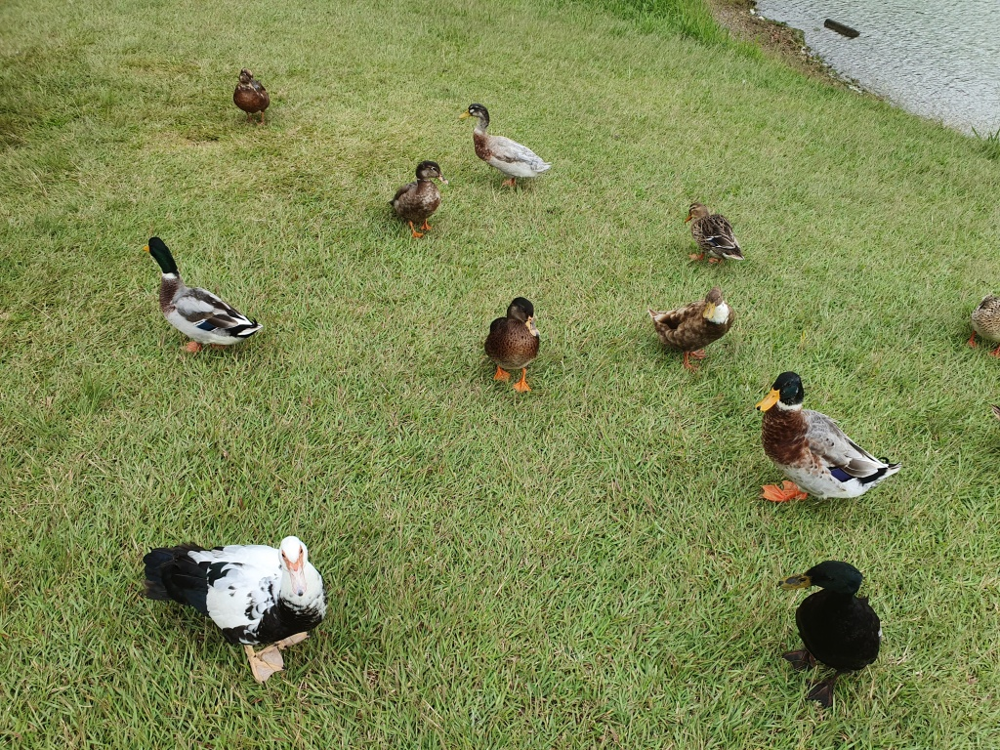

In [35]:
import PIL
fname = 'azorean_ducks.jpg'
PIL.Image.open(fname)

In [36]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.to(device)
res = model(fname)
res[0] # first (and only) image

YOLOv5 <class 'models.common.Detections'> instance
image 1/1: 768x1024 11 birds
Speed: 106.1ms pre-process, 130.5ms inference, 5.9ms NMS per image at shape (1, 3, 480, 640)

In [38]:
boxes = res.boxes.xyxy, res.boxes.conf, res.boxes.cls
boxes

tensor([[ 770.76257,  379.47412,  922.43842,  514.16498],
        [ 662.24164,  291.74191,  753.53430,  386.85977],
        [ 398.66428,  164.31812,  455.25626,  246.68286],
        [ 496.51740,  303.83688,  553.93402,  404.55054],
        [ 797.63098,  572.57587,  904.75598,  731.13251],
        [ 150.29842,  240.08678,  267.05063,  361.53586],
        [ 469.18652,  102.25975,  566.65295,  199.59244],
        [ 700.97919,  206.67027,  763.85632,  272.91000],
        [ 238.05779,   70.11194,  275.66125,  128.42752],
        [ 143.54469,  550.69598,  334.30344,  700.67401],
        [ 987.21478,  300.28348, 1023.53546,  367.01825]], device='cuda:0')

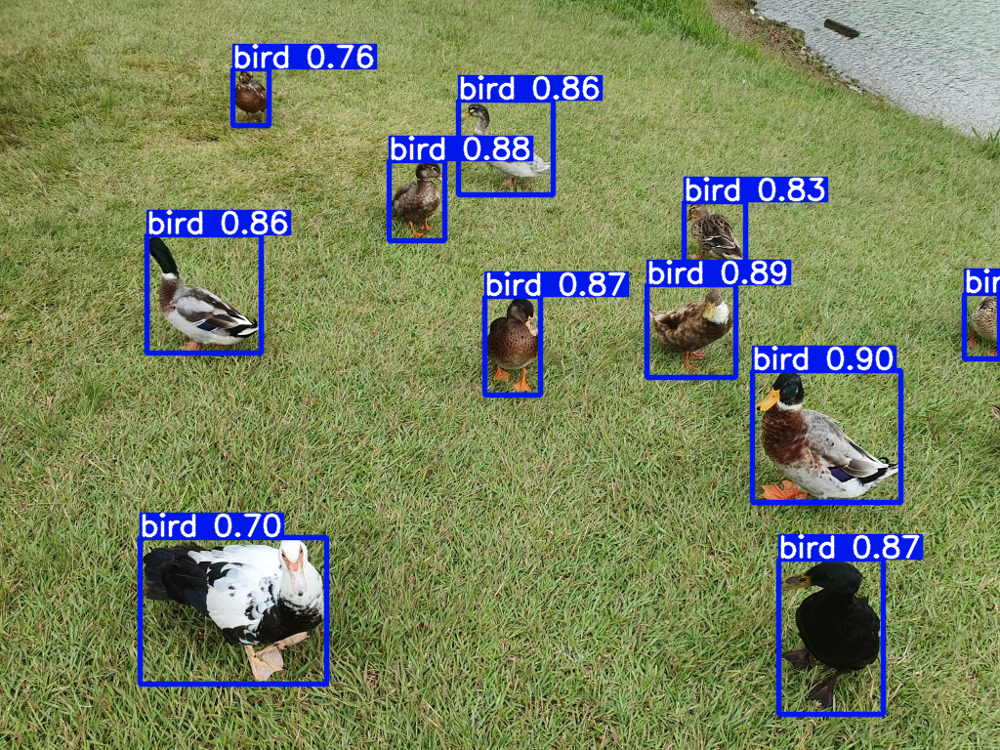

In [39]:
imgs_with_boxes = res.plot()
PIL.Image.fromarray(imgs_with_boxes)

## 14.7 HuggingFace Pipelines for Object Detection

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch0/model_step5.png)

In [40]:
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1
detector = pipeline(model="facebook/detr-resnet-50", task="object-detection", device=device)
res = detector("azorean_ducks.jpg")
res

Could not find image processor class in the image processor config or the model config. Loading based on pattern matching with the model's feature extractor configuration.
The `max_size` parameter is deprecated and will be removed in v4.26. Please specify in `size['longest_edge'] instead`.


[{'score': 0.9894874095916748,
  'label': 'bird',
  'box': {'xmin': 144, 'ymin': 546, 'xmax': 336, 'ymax': 704}},
 {'score': 0.9992701411247253,
  'label': 'bird',
  'box': {'xmin': 496, 'ymin': 303, 'xmax': 553, 'ymax': 406}},
 {'score': 0.9988422989845276,
  'label': 'bird',
  'box': {'xmin': 769, 'ymin': 380, 'xmax': 924, 'ymax': 515}},
 {'score': 0.9970906972885132,
  'label': 'bird',
  'box': {'xmin': 790, 'ymin': 574, 'xmax': 905, 'ymax': 725}},
 {'score': 0.9844100475311279,
  'label': 'bird',
  'box': {'xmin': 992, 'ymin': 303, 'xmax': 1023, 'ymax': 360}},
 {'score': 0.9985462427139282,
  'label': 'bird',
  'box': {'xmin': 472, 'ymin': 105, 'xmax': 566, 'ymax': 197}},
 {'score': 0.9976732134819031,
  'label': 'bird',
  'box': {'xmin': 700, 'ymin': 208, 'xmax': 765, 'ymax': 275}},
 {'score': 0.9973702430725098,
  'label': 'bird',
  'box': {'xmin': 399, 'ymin': 163, 'xmax': 457, 'ymax': 247}},
 {'score': 0.9979994893074036,
  'label': 'bird',
  'box': {'xmin': 238, 'ymin': 67, 'x

In [41]:
boxes = torch.as_tensor([list(v['box'].values()) for v in res])
boxes

tensor([[ 144,  546,  336,  704],
        [ 496,  303,  553,  406],
        [ 769,  380,  924,  515],
        [ 790,  574,  905,  725],
        [ 992,  303, 1023,  360],
        [ 472,  105,  566,  197],
        [ 700,  208,  765,  275],
        [ 399,  163,  457,  247],
        [ 238,   67,  275,  125],
        [ 144,  240,  269,  362],
        [ 661,  298,  753,  382]])

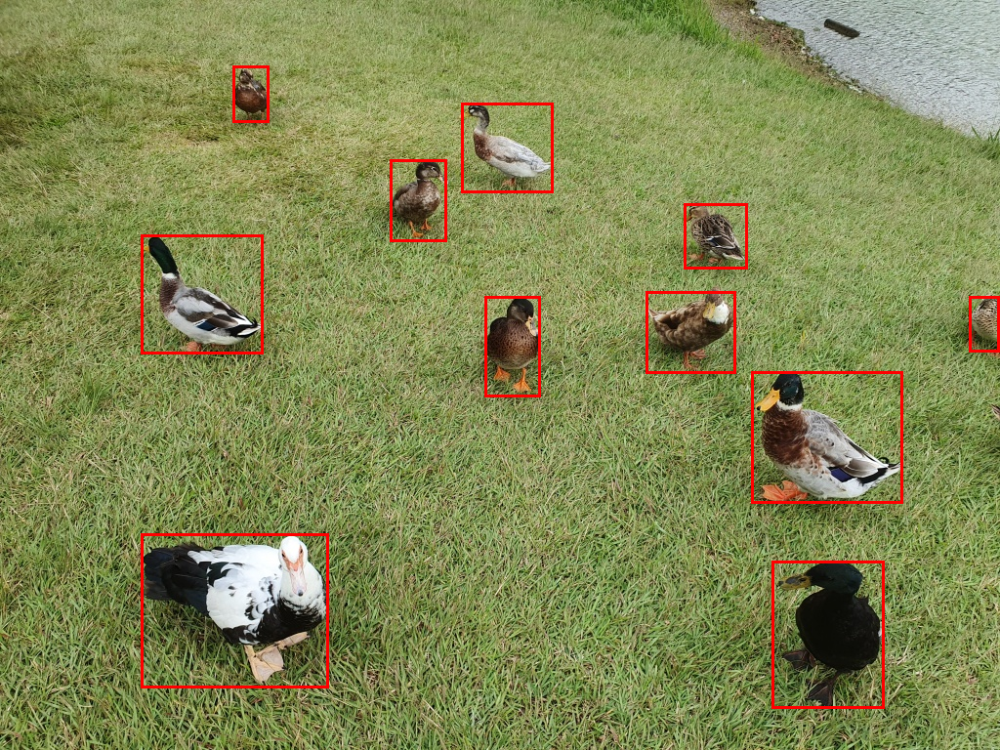

In [42]:
from torchvision.utils import draw_bounding_boxes
from torchvision.transforms import ToImage
from PIL import Image

img = ToImage()(Image.open('azorean_ducks.jpg').convert('RGB'))
result = draw_bounding_boxes(img, boxes, colors=['red']*len(boxes), width=3)
ToPILImage()(result)

In [43]:
detector.model.config.id2label.values()

dict_values(['N/A', 'person', 'traffic light', 'fire hydrant', 'street sign', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'bicycle', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'hat', 'backpack', 'umbrella', 'shoe', 'car', 'eye glasses', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'motorcycle', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'plate', 'wine glass', 'cup', 'fork', 'knife', 'airplane', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'bus', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'mirror', 'dining table', 'window', 'desk', 'train', 'toilet', 'door', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'truck', 'toaster', 'sink', 'refrigerator', 'blender', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'boat', 'toothbrush'])

## 14.8 Zero-Shot Object Detection

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch0/model_step5.png)

In [ ]:
device = 0 if torch.cuda.is_available() else -1
zero_detector = pipeline(model="google/owlvit-base-patch32", task="zero-shot-object-detection", device=device)

In [45]:
res = zero_detector('azorean_ducks.jpg', candidate_labels=['duck', 'goose'])
res

([{'score': 0.46747010946273804,
   'label': 'duck',
   'box': {'xmin': 765, 'ymin': 382, 'xmax': 927, 'ymax': 520}},
  {'score': 0.4318367540836334,
   'label': 'goose',
   'box': {'xmin': 398, 'ymin': 163, 'xmax': 453, 'ymax': 243}},
  {'score': 0.41968658566474915,
   'label': 'duck',
   'box': {'xmin': 142, 'ymin': 233, 'xmax': 272, 'ymax': 368}},
  {'score': 0.41503116488456726,
   'label': 'duck',
   'box': {'xmin': 659, 'ymin': 291, 'xmax': 756, 'ymax': 382}},
  {'score': 0.41497698426246643,
   'label': 'goose',
   'box': {'xmin': 665, 'ymin': 291, 'xmax': 753, 'ymax': 380}},
  {'score': 0.41335687041282654,
   'label': 'duck',
   'box': {'xmin': 468, 'ymin': 102, 'xmax': 568, 'ymax': 198}},
  {'score': 0.4102725088596344,
   'label': 'goose',
   'box': {'xmin': 472, 'ymin': 105, 'xmax': 567, 'ymax': 195}},
  {'score': 0.39043134450912476,
   'label': 'goose',
   'box': {'xmin': 145, 'ymin': 234, 'xmax': 267, 'ymax': 365}},
  {'score': 0.3902215361595154,
   'label': 'goose',
 

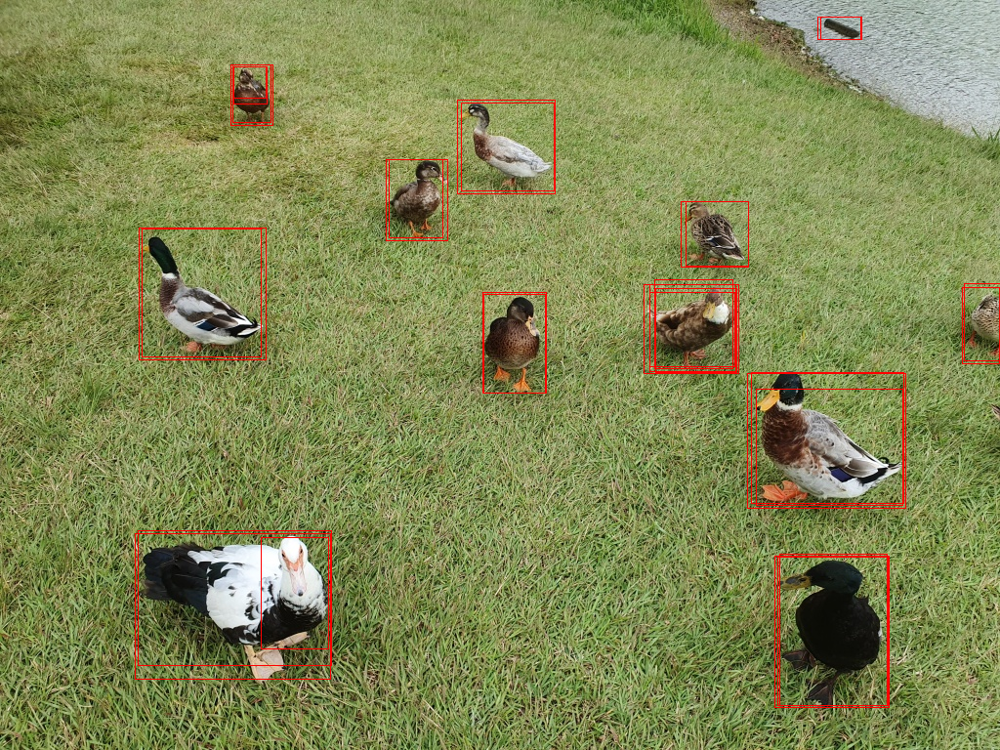

In [46]:
boxes = torch.as_tensor([list(v['box'].values()) for v in res])

img = read_image('azorean_ducks.jpg')
result = draw_bounding_boxes(img, boxes, colors=['red']*len(boxes), width=1)
ToPILImage()(result)

In [47]:
from torchvision.ops import nms

scores = torch.as_tensor([v['score'] for v in res])
box_indices = nms(boxes.float(), scores, iou_threshold=0.1)
box_indices

tensor([ 0,  1,  2,  3,  5,  8,  9, 11, 14, 23, 24, 26])

In [48]:
kept_boxes = boxes[box_indices]
kept_boxes

tensor([[ 765,  382,  927,  520],
        [ 398,  163,  453,  243],
        [ 142,  233,  272,  368],
        [ 659,  291,  756,  382],
        [ 468,  102,  568,  198],
        [ 702,  206,  766,  272],
        [ 495,  301,  558,  402],
        [ 238,   66,  277,  125],
        [ 141,  543,  339,  681],
        [ 837,   17,  881,   40],
        [ 798,  567,  908,  722],
        [ 985,  294, 1023,  372]])

In [49]:
labels = np.array([v['label'] for v in res])
kept_labels = labels[box_indices]
kept_labels

array(['duck', 'goose', 'duck', 'duck', 'duck', 'goose', 'goose', 'goose', 'goose', 'goose', 'goose', 'goose'], dtype='<U5')

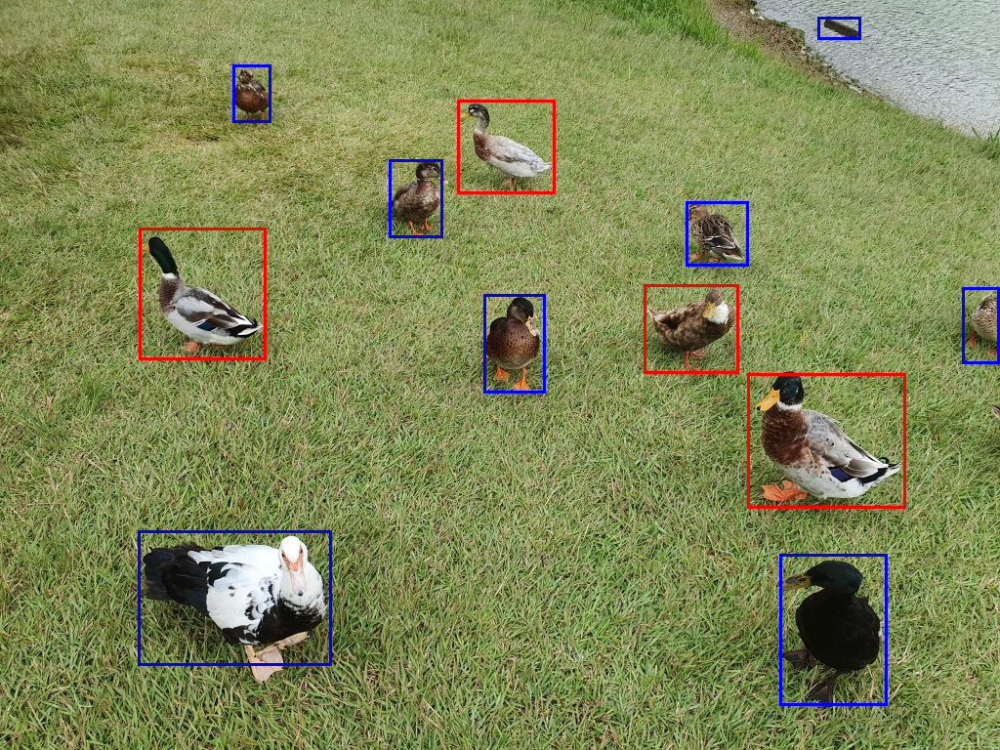

In [50]:
img = read_image('azorean_ducks.jpg')
result = draw_bounding_boxes(img, kept_boxes, colors=['red' if v == 'duck' else 'blue' for v in kept_labels], width=3)
ToPILImage()(result)

### 14.8.1 Grounding Dino

In [ ]:
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

model_id = "IDEA-Research/grounding-dino-tiny"

processor = AutoProcessor.from_pretrained(model_id)
model = AutoModelForZeroShotObjectDetection.from_pretrained(model_id, device_map="auto")

In [ ]:
# Preprocessing
img = ToImage()(Image.open('azorean_ducks.jpg').convert('RGB'))
text_labels = [["the largest duck"]]
inputs = processor(images=img, text=text_labels, return_tensors="pt").to(model.device)

# Prediction
with torch.no_grad():
   outputs = model(**inputs)

# Post-processing
results = processor.post_process_grounded_object_detection(
   outputs,
   inputs.input_ids,
   threshold=0.4,
   text_threshold=0.3,
   target_sizes=[image.size[::-1]]
)

In [ ]:
# Retrieve the first image result
result = results[0]
result = draw_bounding_boxes(img, result['boxes'], colors=['red']*len(boxes), width=3)
ToPILImage()(result)